# GLOF critical area — training and testing

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [2]:
glof = pd.read_csv("glof_clean.csv")
glof.head()

,lake_id,year,lake_area_km2,elevation_m,perimeter_km,area_uncertainty_km2,expansion_rate_km2yr,lake_volume_1e6_m3,dam_height_m,shape_index,...,lon,lat,yrs_capped,already_past_critical,glof_within_50yr,mean_depth,volume_dam,volume_gap,uncertainty_frac,expansion_frac
0,GLO_80.85718_29.91975,2024,0.004988,4782.9,0.36469,0.003,0.0,0.0609,15.00,1.4567,...,80.85718,29.91975,1,0,0,12.209302,0.913500,-0.013920,0.601443,0.0
1,GLO_80.87763_30.04078,2017,0.055611,4448.8,1.25819,0.010,0.0,1.1127,15.99,1.5051,...,80.87763,30.04078,1,0,0,20.008631,17.792073,0.223480,0.179821,0.0
2,GLO_80.87763_30.04078,2018,0.052037,4448.8,1.23996,0.010,0.0,1.0261,15.83,1.5334,...,80.87763,30.04078,1,0,0,19.718662,16.243163,0.202354,0.192171,0.0
3,GLO_80.87763_30.04078,2019,0.055860,4448.8,1.27643,0.010,0.0,1.1188,16.00,1.5235,...,80.87763,30.04078,1,0,0,20.028643,17.900800,0.225040,0.179019,0.0
4,GLO_80.87763_30.04078,2020,0.054780,4448.8,1.22172,0.010,0.0,1.0925,15.95,1.4725,...,80.87763,30.04078,1,0,0,19.943410,17.425375,0.218759,0.182548,0.0


In [3]:
print(glof.shape)
print(glof.columns.tolist())
print(glof["glof_within_50yr"].value_counts())

(11904, 26)
['lake_id', 'year', 'lake_area_km2', 'elevation_m', 'perimeter_km', 'area_uncertainty_km2', 'expansion_rate_km2yr', 'lake_volume_1e6_m3', 'dam_height_m', 'shape_index', 'area_change_km2', 'pct_of_critical_area', 'yrs_to_critical_area', 'expansion_accel_km2yr2', 'dam_stability_index', 'peak_discharge_m3s', 'lon', 'lat', 'yrs_capped', 'already_past_critical', 'glof_within_50yr', 'mean_depth', 'volume_dam', 'volume_gap', 'uncertainty_frac', 'expansion_frac']
glof_within_50yr
0    11677
1      227
Name: count, dtype: int64


In [4]:
# - label out. lake_id is only for grouping.
# - pct and yrs left out (they *are* the target).
# - peak discharge left out (old formula).

FEATURES = [
    "year",
    "lake_area_km2",
    "elevation_m",
    "perimeter_km",
    "area_uncertainty_km2",
    "expansion_rate_km2yr",
    "lake_volume_1e6_m3",
    "dam_height_m",
    "shape_index",
    "expansion_accel_km2yr2",
    "dam_stability_index",
    "lon",
    "lat",
    "mean_depth",
    "volume_gap",
    "uncertainty_frac",
    "expansion_frac",
]
TARGET = "glof_within_50yr"

X = glof[FEATURES]
y = glof[TARGET]
groups = glof["lake_id"]
print(X.shape)
print(y.mean())

(11904, 17)
0.019069220430107527


## sampling

#### as discussed, random slpit defn causes the leakage, thus, we will avoid it

In [5]:
# - stratified on the label: still leaks lakes

X_tr_str, X_te_str, y_tr_str, y_te_str = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
overlap_str = set(glof.loc[X_tr_str.index, "lake_id"]) & set(glof.loc[X_te_str.index, "lake_id"])
print("stratified split, lakes on both sides:", len(overlap_str))
print("positive share train", y_tr_str.mean(), "test", y_te_str.mean())

stratified split, lakes on both sides: 1459
positive share train 0.01904121863799283 test 0.019153225806451613


#### Even the stratified sampling is causing the leakage as there are 1459 identical lakes on both training and testing sets
#### while the target ratio seems to be balanced, but it is causing masssive data leakage

In [6]:
# - grouped by lake: the split we actually use

lakes = glof["lake_id"].drop_duplicates().to_numpy()
np.random.seed(42)
np.random.shuffle(lakes)
cut = int(0.75 * len(lakes))
train_lakes = lakes[:cut]
test_lakes = lakes[cut:]

train_mask = glof["lake_id"].isin(train_lakes)
test_mask = glof["lake_id"].isin(test_lakes)

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]
groups_train = groups[train_mask]

print("grouped split train", len(X_train), "test", len(X_test))
print("lakes on both sides:", len(set(glof.loc[train_mask, "lake_id"]) & set(glof.loc[test_mask, "lake_id"])))
print("positive share train", y_train.mean(), "test", y_test.mean())

grouped split train 8799 test 3105
lakes on both sides: 0
positive share train 0.014660756904193658 test 0.031561996779388084


#### group splitting ensures there are no two same lakes on both sets
#### that said, the data is highly imbalanced

## pipeline

In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, FEATURES),
])

def build(estimator):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [8]:
def class_report(name, y_true, y_pred, y_score=None):
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    print(name)
    print(f"  precision {prec:.3f}")
    print(f"  recall    {rec:.3f}")
    print(f"  roc-auc   {auc:.3f}")
    return {"model": name, "precision": prec, "recall": rec, "roc_auc": auc}

## one model at a time

In [9]:
logreg = build(LogisticRegression(max_iter=1000, class_weight="balanced"))
logreg.fit(X_train, y_train)
pred_log = logreg.predict(X_test)
score_log = logreg.predict_proba(X_test)[:, 1]
class_report("logistic regression", y_test, pred_log, score_log)

logistic regression
  precision 0.875
  recall    1.000
  roc-auc   1.000


{'model': 'logistic regression',
 'precision': 0.875,
 'recall': 1.0,
 'roc_auc': 0.9998405082019506}

In [10]:
tree = build(DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))
tree.fit(X_train, y_train)
pred_tree = tree.predict(X_test)
score_tree = tree.predict_proba(X_test)[:, 1]
class_report("decision tree depth 5", y_test, pred_tree, score_tree)

decision tree depth 5
  precision 0.537
  recall    0.816
  roc-auc   0.898


{'model': 'decision tree depth 5',
 'precision': 0.5369127516778524,
 'recall': 0.8163265306122449,
 'roc_auc': 0.8978743476106772}

In [11]:
forest = build(RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42, n_jobs=-1))
forest.fit(X_train, y_train)
pred_forest = forest.predict(X_test)
score_forest = forest.predict_proba(X_test)[:, 1]
class_report("random forest", y_test, pred_forest, score_forest)

random forest
  precision 0.966
  recall    0.878
  roc-auc   1.000


{'model': 'random forest',
 'precision': 0.9662921348314607,
 'recall': 0.8775510204081632,
 'roc_auc': 0.9996521721425518}

In [12]:
boost = build(HistGradientBoostingClassifier(random_state=42))
boost.fit(X_train, y_train)
pred_boost = boost.predict(X_test)
score_boost = boost.predict_proba(X_test)[:, 1]
class_report("hist gradient boosting", y_test, pred_boost, score_boost)

hist gradient boosting
  precision 0.915
  recall    0.878
  roc-auc   0.999


{'model': 'hist gradient boosting',
 'precision': 0.9148936170212766,
 'recall': 0.8775510204081632,
 'roc_auc': 0.999289073793801}

In [13]:
knn = build(KNeighborsClassifier(n_neighbors=15))
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)
score_knn = knn.predict_proba(X_test)[:, 1]
class_report("knn k=15", y_test, pred_knn, score_knn)

knn k=15
  precision 0.932
  recall    0.704
  roc-auc   0.948


{'model': 'knn k=15',
 'precision': 0.9324324324324325,
 'recall': 0.7040816326530612,
 'roc_auc': 0.9478767230204354}

## cross-validation on train

In [14]:
### stratified kfold vs groupkfold

In [15]:
log_cv = build(LogisticRegression(max_iter=1000, class_weight="balanced"))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gkf = GroupKFold(n_splits=5)

skf_scores = cross_val_score(log_cv, X_train, y_train, cv=skf, scoring="roc_auc", error_score=np.nan)
gkf_scores = cross_val_score(
    log_cv, X_train, y_train, cv=gkf, groups=groups_train, scoring="roc_auc", error_score=np.nan
)

print("stratified kfold AUC", skf_scores.round(3), "mean", round(skf_scores.mean(), 3), "std", round(skf_scores.std(), 3))
print("groupkfold AUC     ", gkf_scores.round(3), "mean", round(gkf_scores.mean(), 3), "std", round(gkf_scores.std(), 3))

stratified kfold AUC [1. 1. 1. 1. 1.] mean 1.0 std 0.0
groupkfold AUC      [1.    0.998 1.    0.995 1.   ] mean 0.999 std 0.002


In [16]:
# - compare families with grouped cv (roc-auc)

candidates = {
    "logistic": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "decision tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "random forest": RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42, n_jobs=-1),
}

cv = GroupKFold(n_splits=5)
rows = []
for name, estimator in candidates.items():
    pipe = build(estimator)
    auc = cross_val_score(
        pipe, X_train, y_train, cv=cv, groups=groups_train, scoring="roc_auc", error_score=np.nan
    )
    rows.append({"model": name, "cv_AUC_mean": auc.mean(), "cv_AUC_std": auc.std()})
    print(name, "AUC", round(auc.mean(), 3), "±", round(auc.std(), 3))

cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

logistic AUC 0.999 ± 0.002
decision tree AUC 0.867 ± 0.085
random forest AUC 0.998 ± 0.002


,cv_AUC_mean,cv_AUC_std
model,,
logistic,0.999,0.002
decision tree,0.867,0.085
random forest,0.998,0.002


## test metrics (once)

In [17]:
rows = []
rows.append(class_report("logistic regression", y_test, pred_log, score_log))
rows.append(class_report("decision tree depth 5", y_test, pred_tree, score_tree))
rows.append(class_report("random forest", y_test, pred_forest, score_forest))
rows.append(class_report("hist gradient boosting", y_test, pred_boost, score_boost))
rows.append(class_report("knn k=15", y_test, pred_knn, score_knn))

test_table = pd.DataFrame(rows).set_index("model").round(3)
test_table

logistic regression
  precision 0.875
  recall    1.000
  roc-auc   1.000
decision tree depth 5
  precision 0.537
  recall    0.816
  roc-auc   0.898
random forest
  precision 0.966
  recall    0.878
  roc-auc   1.000
hist gradient boosting
  precision 0.915
  recall    0.878
  roc-auc   0.999
knn k=15
  precision 0.932
  recall    0.704
  roc-auc   0.948


,precision,recall,roc_auc
model,,,
logistic regression,0.875,1.000,1.000
decision tree depth 5,0.537,0.816,0.898
random forest,0.966,0.878,1.000
hist gradient boosting,0.915,0.878,0.999
knn k=15,0.932,0.704,0.948


In [18]:
print(classification_report(y_test, pred_forest, digits=3, zero_division=0))
cm = confusion_matrix(y_test, pred_forest)
print("tn fp fn tp", cm.ravel())

              precision    recall  f1-score   support

           0      0.996     0.999     0.998      3007
           1      0.966     0.878     0.920        98

    accuracy                          0.995      3105
   macro avg      0.981     0.938     0.959      3105
weighted avg      0.995     0.995     0.995      3105

tn fp fn tp [3004    3   12   86]


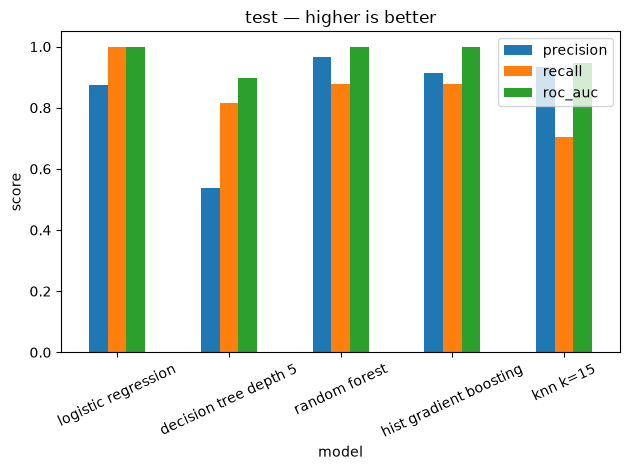

In [19]:
test_table[["precision", "recall", "roc_auc"]].plot.bar(rot=25)
plt.ylabel("score")
plt.title("test — higher is better")
plt.tight_layout()
plt.show()

## perceptron

same yes/no target. a linear perceptron is the cheap check for later deep learning.

if it is close to the forest, a neural net is unlikely to earn its cost. if it is weak, trees already cover the non-linear part.


In [20]:
perceptron = build(Perceptron())
perceptron.fit(X_train, y_train)
pred_p = perceptron.predict(X_test)
score_p = perceptron.decision_function(X_test)
class_report("perceptron", y_test, pred_p, score_p)

perceptron
  precision 0.890
  recall    0.990
  roc-auc   1.000


{'model': 'perceptron',
 'precision': 0.8899082568807339,
 'recall': 0.9897959183673469,
 'roc_auc': 0.9995317049333867}

In [21]:
clf_candidates = {
    "perceptron": Perceptron(),
    "logistic": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "random forest clf": RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42, n_jobs=-1),
}

rows = []
for name, estimator in clf_candidates.items():
    pipe = build(estimator)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    if hasattr(pipe.named_steps["model"], "predict_proba"):
        score = pipe.predict_proba(X_test)[:, 1]
    else:
        score = pipe.decision_function(X_test)
    rows.append(class_report(name, y_test, pred, score))

pd.DataFrame(rows).set_index("model").round(3)

perceptron
  precision 0.890
  recall    0.990
  roc-auc   1.000
logistic
  precision 0.875
  recall    1.000
  roc-auc   1.000
random forest clf
  precision 0.966
  recall    0.878
  roc-auc   1.000


,precision,recall,roc_auc
model,,,
perceptron,0.890,0.990,1.0
logistic,0.875,1.000,1.0
random forest clf,0.966,0.878,1.0


## why the score looks perfect

positive class is about 2%. ROC-AUC can look perfect when the few positive lakes are just the big ones.

average precision is the number that matches that imbalance. a single size column already ranks them.


In [22]:
from sklearn.metrics import average_precision_score

print("positive share", round(y.mean(), 4), "count", int(y.sum()))

rows = []
for col in FEATURES:
    score = X[col]
    auc_pos = roc_auc_score(y, score)
    auc_neg = roc_auc_score(y, -score)
    if auc_pos >= auc_neg:
        auc, used = auc_pos, score
    else:
        auc, used = auc_neg, -score
    rows.append({
        "feature": col,
        "roc_auc": auc,
        "average_precision": average_precision_score(y, used),
    })

one_col = pd.DataFrame(rows).sort_values("average_precision", ascending=False)
print(one_col.round(3).to_string(index=False))
print()
print(glof.groupby("glof_within_50yr")[["lake_area_km2", "expansion_rate_km2yr"]].median())

positive share 0.0191 count 227
               feature  roc_auc  average_precision
    lake_volume_1e6_m3    0.961              0.709
         lake_area_km2    0.960              0.708
            mean_depth    0.961              0.708
      uncertainty_frac    0.960              0.707
  area_uncertainty_km2    0.960              0.700
  expansion_rate_km2yr    0.827              0.688
            volume_gap    0.959              0.688
          perimeter_km    0.962              0.678
   dam_stability_index    0.947              0.669
          dam_height_m    0.944              0.589
           shape_index    0.877              0.190
        expansion_frac    0.732              0.060
expansion_accel_km2yr2    0.517              0.052
                   lon    0.629              0.031
                   lat    0.618              0.026
           elevation_m    0.517              0.025
                  year    0.515              0.019

                  lake_area_km2  expansion_rate_k

area alone is already a strong ranker. the full model is mostly reading lake size, not a hidden GLOF signal. SMOTE rebalances training rows. it does not remove that size signal.


## mlflow

In [23]:
import logging
from pathlib import Path

import mlflow
import mlflow.sklearn

logging.getLogger("mlflow").setLevel(logging.WARNING)

ROOT = Path.cwd()
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
mlflow.set_experiment("glof-critical-area")

print("tracking:", mlflow.get_tracking_uri())
print("mlflow ui --backend-store-uri sqlite:///mlflow.db")

tracking: sqlite:////Users/kushalthapa/Desktop/Applied ML/Applied_ML_GLOF_prediction/notebooks/mlflow.db
mlflow ui --backend-store-uri sqlite:///mlflow.db


In [24]:
# - log the two families we keep: logistic and a tree model
# - average precision, not roc, because the class is rare

tracked = {
    "logistic": logreg,
    "random-forest": forest,
    "hist-boosting": boost,
}

cv = GroupKFold(n_splits=5)

for run_name, candidate in tracked.items():
    with mlflow.start_run(run_name=run_name):
        fold_scores = cross_val_score(
            candidate,
            X_train,
            y_train,
            cv=cv,
            groups=groups_train,
            scoring="average_precision",
        )
        test_probabilities = candidate.predict_proba(X_test)[:, 1]

        mlflow.log_param("estimator", candidate.named_steps["model"].__class__.__name__)
        mlflow.log_param("split", "group by lake")
        mlflow.log_param("sampling", "none")
        mlflow.log_metric("cv_average_precision", fold_scores.mean())
        mlflow.log_metric("cv_std", fold_scores.std())
        mlflow.log_metric("test_average_precision", average_precision_score(y_test, test_probabilities))
        mlflow.log_metric("test_roc_auc", roc_auc_score(y_test, test_probabilities))
        mlflow.sklearn.log_model(candidate, name="model")

        print(f"logged {run_name}: cv AP {fold_scores.mean():.3f} ± {fold_scores.std():.3f}")

MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype'].

In [ ]:
runs = mlflow.search_runs(experiment_names=["glof-critical-area"])
comparison = runs[[
    "tags.mlflow.runName",
    "params.estimator",
    "metrics.cv_average_precision",
    "metrics.test_average_precision",
    "metrics.test_roc_auc",
]]
comparison.columns = ["run", "estimator", "cv_AP", "test_AP", "test_AUC"]
print(comparison.round(3).to_string(index=False))

## model selection

two families: logistic regression, and hist gradient boosting.

tune inside grouped cross-validation. score with average precision. try SMOTE only on the training fold.


In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV

def build_smote(estimator):
    return ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42, k_neighbors=3)),
        ("model", estimator),
    ])

In [ ]:
# - plain vs SMOTE, before the grid

pairs = {
    "logistic": build(LogisticRegression(max_iter=1000)),
    "logistic smote": build_smote(LogisticRegression(max_iter=1000)),
    "hist boosting": build(HistGradientBoostingClassifier(random_state=42)),
    "hist boosting smote": build_smote(HistGradientBoostingClassifier(random_state=42)),
}

cv = GroupKFold(n_splits=5)
rows = []
for name, pipe in pairs.items():
    scores = cross_val_score(
        pipe, X_train, y_train, cv=cv, groups=groups_train, scoring="average_precision"
    )
    rows.append({"model": name, "cv_AP": scores.mean(), "cv_std": scores.std()})
    print(name, round(scores.mean(), 3), "±", round(scores.std(), 3))

pd.DataFrame(rows).set_index("model").round(3)

In [ ]:
log_search = GridSearchCV(
    build_smote(LogisticRegression(max_iter=1000)),
    {"model__C": [0.1, 1, 10]},
    cv=GroupKFold(n_splits=5),
    scoring="average_precision",
    n_jobs=-1,
)
log_search.fit(X_train, y_train, groups=groups_train)
print("logistic", log_search.best_params_, round(log_search.best_score_, 3))

boost_search = GridSearchCV(
    build_smote(HistGradientBoostingClassifier(random_state=42)),
    {"model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 6]},
    cv=GroupKFold(n_splits=5),
    scoring="average_precision",
    n_jobs=-1,
)
boost_search.fit(X_train, y_train, groups=groups_train)
print("hist boosting", boost_search.best_params_, round(boost_search.best_score_, 3))

In [ ]:
# - test once, on the tuned pipes

for run_name, search in {"logistic-smote-tuned": log_search, "hist-boosting-smote-tuned": boost_search}.items():
    model = search.best_estimator_
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({k: str(v) for k, v in search.best_params_.items()})
        mlflow.log_param("sampling", "SMOTE")
        mlflow.log_param("split", "group by lake")
        mlflow.log_metric("cv_average_precision", search.best_score_)
        mlflow.log_metric("test_average_precision", average_precision_score(y_test, proba))
        mlflow.log_metric("test_roc_auc", roc_auc_score(y_test, proba))
        mlflow.log_metric("test_precision", precision_score(y_test, pred, zero_division=0))
        mlflow.log_metric("test_recall", recall_score(y_test, pred, zero_division=0))
        mlflow.sklearn.log_model(model, name="model")
    print(run_name)
    print("  cv AP", round(search.best_score_, 3))
    print("  test AP", round(average_precision_score(y_test, proba), 3))
    print("  precision", round(precision_score(y_test, pred, zero_division=0), 3))
    print("  recall", round(recall_score(y_test, pred, zero_division=0), 3))

In [ ]:
runs = mlflow.search_runs(experiment_names=["glof-critical-area"])
keep = runs[runs["tags.mlflow.runName"].notna()]
print(keep[[
    "tags.mlflow.runName",
    "metrics.cv_average_precision",
    "metrics.test_average_precision",
    "metrics.test_roc_auc",
]].round(3).to_string(index=False))